# 05 · Word2Vec and GloVe for Text Classification (Module III)

**Theory.** Word embeddings map each word to a dense vector (here 100 numbers) so that words used in
similar contexts end up close together. **Word2Vec** learns them with a shallow neural network that
predicts context: *CBOW* predicts a word from its surrounding window, *skip-gram* predicts the
surrounding words from the centre word (trained with negative sampling). **GloVe** instead builds a
global word–word co-occurrence matrix and factorises it, so that `wi·wj + bi + bj ≈ log X_ij`
(X_ij = how often j appears near i). To classify a document we average its word vectors. This is
cheap, but **averaging throws away word order** ("dog bites man" = "man bites dog").

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import src.utils  # FIRST: sets cache folders before gensim.downloader / transformers are imported

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gensim.downloader as api
from gensim.models import Word2Vec
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE

from src.utils import FAST, MODELS, SEED
from src.data import AG_LABELS, load
from src.preprocess import clean
from src.evaluate import classification_metrics, plot_confusion, save_results

print("FAST mode:", FAST)

FAST mode: False


## Tokens
`clean(text, lemma=False)`: lowercase, NLTK tokens, punctuation and stop words removed. We do **not**
lemmatize, because GloVe's vocabulary holds surface forms ("said", "companies").

In [2]:
train, test = load("ag_train"), load("ag_test")
t0 = time.perf_counter()
train_tok = [clean(t, lemma=False).split() for t in train.text]
test_tok = [clean(t, lemma=False).split() for t in test.text]
tok_secs = time.perf_counter() - t0
print(f"tokenized {len(train_tok) + len(test_tok):,} docs in {tok_secs:.1f}s")
print(train_tok[0])

tokenized 37,600 docs in 4.1s
['powell', 'worsening', 'insurgency', 'makes', 'election', 'difficult', 'iraq', 'us', 'secretary', 'state', 'colin', 'powell', 'said', 'sunday', 'escalating', 'insurgency', 'iraq', 'could', 'make', 'organizing', 'election', 'country', 'difficult', 'atleast', '16', 'people', 'killed', 'rebel', 'attacks', 'iraq']


## Train Word2Vec on the AG training text: CBOW vs skip-gram
Only the 30k *training* documents are used, so the test set stays unseen. `workers=1` plus
`PYTHONHASHSEED=0` (set by `scripts/run_nb.sh`) makes training repeatable.

In [3]:
W2V_ARGS = dict(vector_size=100, window=5, min_count=2, epochs=10, workers=1, seed=SEED)
w2v, w2v_secs = {}, {}
for name, sg in [("cbow", 0), ("skipgram", 1)]:
    t = time.perf_counter()
    w2v[name] = Word2Vec(sentences=train_tok, sg=sg, **W2V_ARGS).wv  # .wv = the word vectors only
    w2v_secs[name] = time.perf_counter() - t
    print(f"{name:9s} vocab {len(w2v[name]):,}  trained in {w2v_secs[name]:.1f}s")

cbow      vocab 27,817  trained in 7.2s


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


skipgram  vocab 27,817  trained in 24.1s


If you see `Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'` above: it is a
harmless message from gensim's compiled code, not a training failure. When a dot product happens to
equal exactly −1.0 (Cython's error sentinel), Cython checks for an error, finds none, and prints this
line anyway. We verified no Python exception is raised, the vectors contain no NaN, and the neighbours
below are sensible.

## Load pre-trained GloVe (Wikipedia + Gigaword, 6B tokens, 400k words)

In [4]:
t = time.perf_counter()
glove = api.load("glove-wiki-gigaword-100")
glove_load_secs = time.perf_counter() - t
print(f"GloVe: {len(glove):,} words × {glove.vector_size} dims, loaded in {glove_load_secs:.1f}s")

GloVe: 400,000 words × 100 dims, loaded in 19.6s


## Nearest neighbours: what each space learned

In [5]:
probe_words = ["oil", "microsoft", "football", "iraq", "profit"]
rows = []
for w in probe_words:
    for name, kv in [("w2v cbow", w2v["cbow"]), ("w2v skip-gram", w2v["skipgram"]), ("glove", glove)]:
        nn = kv.most_similar(w, topn=5) if w in kv else []
        rows.append({"word": w, "model": name, "top-5 neighbours": ", ".join(f"{x} ({s:.2f})" for x, s in nn)})
pd.set_option("display.max_colwidth", 120)
pd.DataFrame(rows).set_index(["word", "model"])

top-5 neighbours
word      model                                                                                                        
oil       w2v cbow                           petrol (0.77), crude-oil (0.73), crude (0.73), fuel (0.72), 10-gbps (0.71)
          w2v skip-gram                  crude (0.87), producers (0.74), barrel (0.73), prices (0.73), crude-oil (0.69)
          glove                                  petroleum (0.79), crude (0.78), gas (0.76), fuel (0.70), energy (0.69)
microsoft w2v cbow                              msft (0.71), windows (0.71), msft.o (0.70), longhorn (0.70), sp2 (0.70)
          w2v skip-gram                               windows (0.77), msft (0.74), xp (0.69), sp2 (0.68), msft.o (0.66)
          glove                               google (0.81), netscape (0.79), ibm (0.79), intel (0.79), software (0.78)
football  w2v cbow                            nhl (0.83), college (0.81), bourque (0.79), hockey (0.79), bettman (0.79)
          w2v skip-gram             intro (0.69), coaching (0.68), housewives (0.67), claymores (0.67), referees (0.66)
          glove                            soccer (0.87), basketball (0.86), league (0.82), rugby (0.80), hockey (0.78)
iraq      w2v cbow                           iraqi (0.80), us-led (0.75), hostage (0.74), captors (0.73), troops (0.72)
          w2v skip-gram                   iraqi (0.79), baghdad (0.77), iraqis (0.69), us-led (0.68), insurgents (0.66)
          glove                            afghanistan (0.84), iraqi (0.83), baghdad (0.78), saddam (0.78), iran (0.77)
profit    w2v cbow       quarterly (0.93), earnings (0.92), third-quarter (0.90), profits (0.89), fourth-quarter (0.87)
          w2v skip-gram              earnings (0.85), quarterly (0.84), third-quarter (0.81), profits (0.78), 3q (0.77)
          glove                               profits (0.90), earnings (0.89), net (0.81), revenue (0.81), sales (0.78)

Our Word2Vec was trained on only ~0.8M tokens of 2004 news, so its neighbours are *topical*
(words from the same stories). GloVe saw 6B tokens and gives cleaner *semantic* neighbours.

## One analogy: king − man + woman ≈ ?

In [6]:
for name, kv in [("w2v cbow", w2v["cbow"]), ("w2v skip-gram", w2v["skipgram"]), ("glove", glove)]:
    if all(w in kv for w in ["king", "man", "woman"]):
        print(f"{name:14s}", kv.most_similar(positive=["king", "woman"], negative=["man"], topn=3))
    else:
        print(f"{name:14s} missing words:", [w for w in ["king", "man", "woman"] if w not in kv])
print("glove (news analogy) paris - france + japan:",
      glove.most_similar(positive=["paris", "japan"], negative=["france"], topn=3))

w2v cbow       [('penh', 0.8357787728309631), ('phnom', 0.8010305166244507), ('president-elect', 0.7802907228469849)]
w2v skip-gram  [('norodom', 0.62375408411026), ('sihanouk', 0.6103184819221497), ('penh', 0.5835272669792175)]
glove          [('queen', 0.7698540687561035), ('monarch', 0.6843381524085999), ('throne', 0.6755736470222473)]
glove (news analogy) paris - france + japan: [('tokyo', 0.899385929107666), ('osaka', 0.7420608401298523), ('japanese', 0.7059353590011597)]


Analogies need a lot of varied text. In 2004 AG News, "king" is mostly Cambodia's King Sihanouk, so
our Word2Vec answers with Cambodian names. GloVe (6B tokens) recovers *queen*, and even
*paris − france + japan ≈ tokyo*.
Note also *microsoft*: our vectors give its products (windows, xp), while GloVe gives its competitors
(google, ibm). Small in-domain training captures "appears in the same stories"; big general corpora
capture "plays the same role".

## Document vector = mean of its word vectors (OOV words skipped)

In [7]:
def doc_vectors(token_lists, kv):
    """Average the vectors of the in-vocabulary words; an all-OOV document gets a zero vector."""
    X = np.zeros((len(token_lists), kv.vector_size), dtype=np.float32)
    n_tok = n_oov = n_empty = 0
    for i, toks in enumerate(token_lists):
        known = [w for w in toks if w in kv.key_to_index]
        n_tok += len(toks); n_oov += len(toks) - len(known)
        if known:
            X[i] = kv[known].mean(axis=0)
        else:
            n_empty += 1
    return X, n_oov / max(n_tok, 1), n_empty

features, oov = {}, {}
for name, kv in [("Word2Vec CBOW", w2v["cbow"]), ("Word2Vec skip-gram", w2v["skipgram"]), ("GloVe", glove)]:
    t = time.perf_counter()
    Xtr, oov_tr, _ = doc_vectors(train_tok, kv)
    Xte, oov_te, empty_te = doc_vectors(test_tok, kv)
    features[name] = (Xtr, Xte, (time.perf_counter() - t) / (len(Xtr) + len(Xte)) * 1000)
    oov[name] = {"train_oov_rate": round(oov_tr, 4), "test_oov_rate": round(oov_te, 4), "test_all_oov_docs": empty_te}
pd.DataFrame(oov).T

,train_oov_rate,test_oov_rate,test_all_oov_docs
Word2Vec CBOW,0.0257,0.0460,0.0
Word2Vec skip-gram,0.0257,0.0460,0.0
GloVe,0.0153,0.0151,0.0


Word2Vec's training OOV rate is only the words seen once (`min_count=2`). On *test* text, any word
that never appeared in 30k AG documents is lost. GloVe's 400k vocabulary covers more test words.

## Logistic regression on the averaged vectors (AG test set, 7,600 docs)

In [8]:
rows, fitted = [], {}
clean_ms = tok_secs / (len(train_tok) + len(test_tok)) * 1000
for name, (Xtr, Xte, vec_ms) in features.items():
    clf = LogisticRegression(max_iter=2000, random_state=SEED)
    t = time.perf_counter(); clf.fit(Xtr, train.label); fit_s = time.perf_counter() - t
    t = time.perf_counter(); pred = clf.predict(Xte); pred_ms = (time.perf_counter() - t) / len(Xte) * 1000
    m = classification_metrics(test.label, pred, AG_LABELS)
    kv = glove if name == "GloVe" else w2v["skipgram" if "skip" in name else "cbow"]
    emb_train_s = 0.0 if name == "GloVe" else w2v_secs["skipgram" if "skip" in name else "cbow"]
    fitted[name] = dict(pred=pred, metrics=m, fit_s=fit_s, emb_train_s=emb_train_s,
                        infer_ms=clean_ms + vec_ms + pred_ms,
                        size_mb=kv.vectors.nbytes / 1e6 + clf.coef_.nbytes / 1e6)
    rows.append({"model": name, "accuracy": m["accuracy"], "macro_P": m["macro_precision"],
                 "macro_R": m["macro_recall"], "macro_F1": m["macro_f1"],
                 "embedding train s": round(emb_train_s, 1), "LR fit s": round(fit_s, 1),
                 "infer ms/doc": round(fitted[name]["infer_ms"], 3),
                 "size MB (vectors)": round(fitted[name]["size_mb"], 1)})
results = pd.DataFrame(rows).set_index("model")
results

,accuracy,macro_P,macro_R,macro_F1,embedding train s,LR fit s,infer ms/doc,size MB (vectors)
model,,,,,,,,
Word2Vec CBOW,0.8683,0.8680,0.8683,0.8681,7.2,0.4,0.135,11.1
Word2Vec skip-gram,0.8861,0.8859,0.8861,0.8860,24.1,0.2,0.134,11.1
GloVe,0.8828,0.8826,0.8828,0.8827,0.0,0.3,0.135,160.0


Skip-gram beats CBOW clearly, and ends up level with GloVe even though it has ~3× GloVe's test OOV
rate: vectors trained on the task's own domain make up for a small corpus. CBOW averages its context
window, which blurs the rarer, topic-specific words that matter most here.

For reference, TF-IDF + the same logistic regression scored the accuracy printed below (from
`results/tfidf.json`, nb02). Averaged embeddings compress each document into 100 numbers and lose
which exact words appeared, so on a topic task with strong keywords, sparse TF-IDF is hard to beat.

In [9]:
import json
from src.utils import RESULTS
print("TF-IDF uni+bigram accuracy:", json.loads((RESULTS / "tfidf.json").read_text())["metrics"]["accuracy"])

TF-IDF uni+bigram accuracy: 0.9018


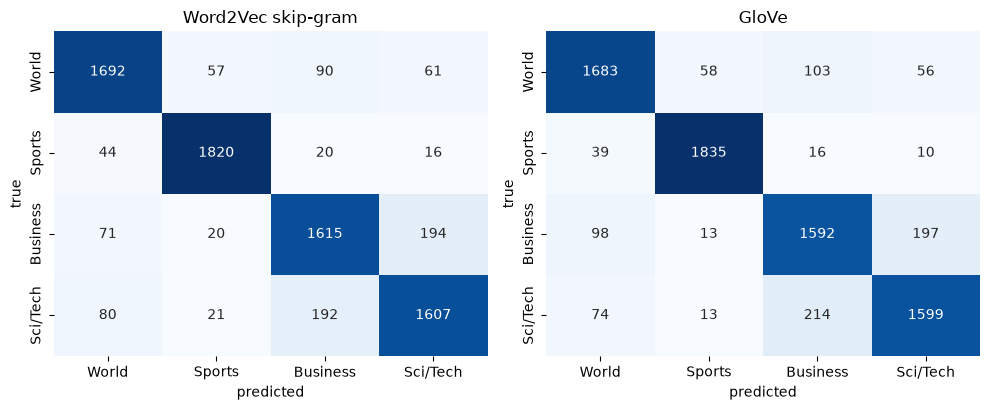

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, name in zip(axes, ["Word2Vec skip-gram", "GloVe"]):
    plot_confusion(test.label, fitted[name]["pred"], AG_LABELS, ax=ax, title=name)
plt.tight_layout(); plt.show()

## t-SNE of document vectors (1,000 test documents)
t-SNE squeezes 100 dimensions into 2 while trying to keep near neighbours near. Only the grouping is
meaningful, not the axes or the distances between clusters.

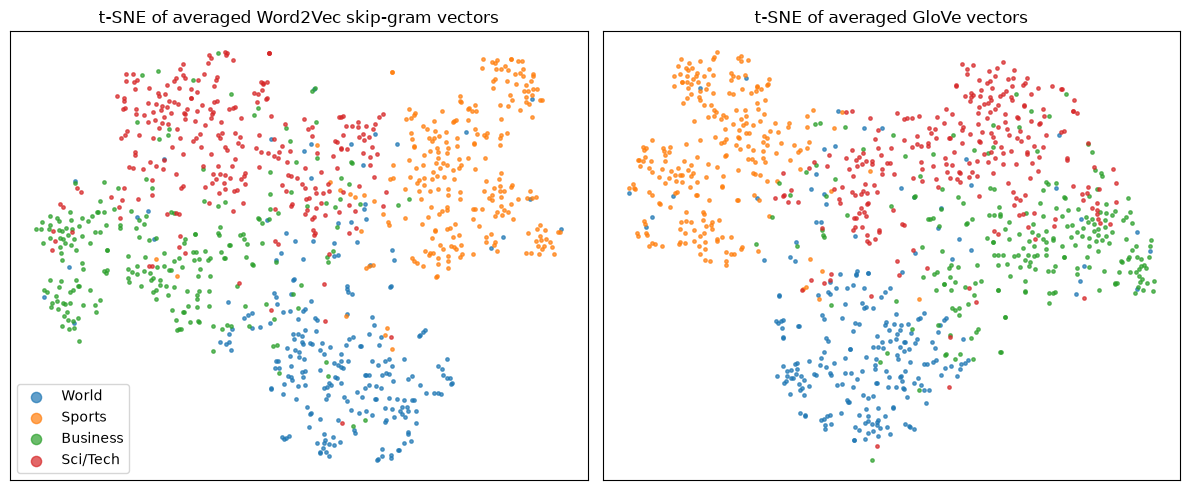

In [11]:
idx = np.random.default_rng(SEED).choice(len(test), size=1000, replace=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, name in zip(axes, ["Word2Vec skip-gram", "GloVe"]):
    xy = TSNE(n_components=2, random_state=SEED, init="pca", perplexity=30).fit_transform(features[name][1][idx])
    for c, lab in enumerate(AG_LABELS):
        mask = test.label.to_numpy()[idx] == c
        ax.scatter(xy[mask, 0], xy[mask, 1], s=6, label=lab, alpha=0.7)
    ax.set_title(f"t-SNE of averaged {name} vectors"); ax.set_xticks([]); ax.set_yticks([])
axes[0].legend(markerscale=3)
plt.tight_layout(); plt.show()

Sports forms the tightest cluster (a very distinctive vocabulary). Business and Sci/Tech overlap:
the same confusion the classifiers make.

## Why domain match matters
The same GloVe algorithm trained on tweets (`glove-twitter-100`, used in nb11) would fit news worse:
its neighbours reflect how words are used on Twitter. We pick the Wikipedia+Gigaword (newswire) vectors
for news and the Twitter vectors for tweets. Our own Word2Vec is perfectly in-domain but tiny, which is
why it has more OOV test words and noisier neighbours.

In [12]:
if not FAST:
    MODELS.mkdir(exist_ok=True)
    w2v["skipgram"].save(str(MODELS / "w2v_ag_skipgram.kv"))  # static vectors reused in nb07 ("bank")
    print("saved models/w2v_ag_skipgram.kv")

for family, main in [("word2vec", "Word2Vec skip-gram"), ("glove", "GloVe")]:
    f = fitted[main]
    save_results(family, {
        "dataset": "ag_news", "n_train": len(train), "n_test": len(test), "config": main + " mean + LR",
        "metrics": f["metrics"], "train_time_s": round(f["emb_train_s"] + f["fit_s"], 2),
        "infer_ms_per_doc": round(f["infer_ms"], 3), "model_size_mb": round(f["size_mb"], 1),
        "oov": oov[main],
        "variants": results.reset_index().to_dict("records") if family == "word2vec" else [],
        "y_pred": f["pred"],
    })

saved models/w2v_ag_skipgram.kv
saved results/word2vec.json
saved results/glove.json


## Viva notes
**Q1. CBOW vs skip-gram?**
CBOW predicts the centre word from the average of its context words: faster, and good for frequent
words. Skip-gram predicts each context word from the centre word: slower, but it gives rare words
more training signal, so it usually represents them better.

**Q2. Word2Vec vs GloVe?**
Word2Vec is *predictive*: it slides a window and trains a small network with local context.
GloVe is *count-based*: it first counts global co-occurrences over the whole corpus, then fits
vectors whose dot products match the log counts. Both give static vectors, one per word type.

**Q3. Why do averaged embeddings lose information?**
The mean is the same for any order of the words, so syntax and negation scope are lost, and 30 words
are squeezed into 100 numbers. Rare but decisive keywords get diluted by the other words, which
TF-IDF keeps as separate features.